<a href="https://colab.research.google.com/github/nabeeha-rafi/digital-advertising-budget-optimizer-/blob/main/budget_optimizer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ==============================================================================
# DAY 1 MILESTONE: BIG DATA ADVERTISING SIMULATOR & SCHEMA PIPELINE
# ==============================================================================

import numpy as np
import pandas as pd
import time

def generate_ad_data(n_rows: int = 10_000, seed: int = 42) -> pd.DataFrame:
    """
    Generates realistic Pakistani e-commerce digital advertising data across
    Facebook, Instagram, Google, TikTok, and YouTube.
    Anchored to Project 1 (Daraz Pakistan) mid-week peaks and value drivers.
    """
    rng = np.random.default_rng(seed)

    platforms = ["Facebook", "Instagram", "Google", "TikTok", "YouTube"]
    platform_probs = np.array([0.26, 0.24, 0.22, 0.16, 0.12])

    campaigns = [
        "Daraz_Quality_Miyaar_2026",   # Linked to Project 1 top keyword: 'miyaar'
        "Daraz_Qeemat_Flash_Sale",     # Linked to Project 1 top keyword: 'qeemat'
        "Top_SKU_Retargeting",         # Linked to Project 1 top SKU: MA305FA1KY528NAFAMZ
        "Midweek_Payday_Boost",        # Linked to Project 1 Wed/Thu engagement peak
        "Brand_Awareness_PK",
    ]

    cities = ["Karachi", "Lahore", "Islamabad", "Rawalpindi", "Faisalabad", "Multan"]
    city_probs = np.array([0.32, 0.28, 0.14, 0.10, 0.09, 0.07])

    ages = ["18-24", "25-34", "35-44", "45-54", "55+"]
    age_probs = np.array([0.28, 0.42, 0.18, 0.08, 0.04])

    genders = ["Male", "Female"]
    gender_probs = np.array([0.58, 0.42])

    devices = ["Android", "iOS", "Desktop"]
    device_probs = np.array([0.68, 0.22, 0.10])

    # 180-day campaign window
    start_date = np.datetime64("2026-05-01")
    day_offsets = rng.integers(0, 180, size=n_rows, dtype=np.int32)
    dates = start_date + day_offsets.astype("timedelta64[D]")

    plat_idx = rng.choice(len(platforms), size=n_rows, p=platform_probs).astype(np.int8)
    camp_idx = rng.integers(0, len(campaigns), size=n_rows, dtype=np.int8)
    city_idx = rng.choice(len(cities), size=n_rows, p=city_probs).astype(np.int8)
    age_idx = rng.choice(len(ages), size=n_rows, p=age_probs).astype(np.int8)
    gen_idx = rng.choice(len(genders), size=n_rows, p=gender_probs).astype(np.int8)
    dev_idx = rng.choice(len(devices), size=n_rows, p=device_probs).astype(np.int8)

    # Platform-specific funnel parameters [Facebook, Instagram, Google, TikTok, YouTube]
    base_imp = np.array([14000, 12500, 9500, 18000, 16000])[plat_idx]
    impressions = np.maximum(500, (base_imp * rng.lognormal(0.0, 0.45, size=n_rows)).astype(np.int64))

    base_ctr = np.array([0.018, 0.024, 0.042, 0.016, 0.014])[plat_idx]
    ctr = np.clip(base_ctr * rng.normal(1.0, 0.25, size=n_rows), 0.003, 0.15)
    clicks = np.maximum(1, np.round(impressions * ctr).astype(np.int64))

    # CPC in Pakistani Rupees (Rs.)
    base_cpc = np.array([18.0, 22.0, 45.0, 14.0, 20.0])[plat_idx]
    cpc = np.maximum(3.0, base_cpc * rng.normal(1.0, 0.22, size=n_rows))
    spend = np.round(clicks * cpc, 2)

    # Conversion Rate (CVR) with Wed/Thu mid-week uplift from Project 1
    base_cvr = np.array([0.032, 0.041, 0.068, 0.021, 0.019])[plat_idx]
    dow = day_offsets % 7  # 2026-05-01 is Friday -> 5=Wednesday, 6=Thursday
    midweek_boost = np.where((dow == 5) | (dow == 6), 1.15, 1.0)
    camp_boost = np.array([1.10, 1.05, 1.25, 1.08, 0.85])[camp_idx]
    cvr = np.clip(base_cvr * midweek_boost * camp_boost * rng.normal(1.0, 0.25, size=n_rows), 0.002, 0.30)
    conversions = np.round(clicks * cvr).astype(np.int64)

    # Average Order Value (Rs.) -> Revenue
    base_aov = np.array([2400.0, 2750.0, 3200.0, 1950.0, 2600.0])[plat_idx]
    aov = np.maximum(500.0, base_aov * rng.normal(1.0, 0.20, size=n_rows))
    revenue = np.round(conversions * aov, 2)

    df = pd.DataFrame({
        "date": dates,
        "campaign": pd.Categorical.from_codes(camp_idx, categories=campaigns),
        "platform": pd.Categorical.from_codes(plat_idx, categories=platforms),
        "impressions": impressions,
        "clicks": clicks,
        "spend": spend,
        "conversions": conversions,
        "revenue": revenue,
        "age": pd.Categorical.from_codes(age_idx, categories=ages),
        "gender": pd.Categorical.from_codes(gen_idx, categories=genders),
        "city": pd.Categorical.from_codes(city_idx, categories=cities),
        "device": pd.Categorical.from_codes(dev_idx, categories=devices),
    })
    return df

# Generate baseline 10K dataset and export for Day 2
df_10k = generate_ad_data(n_rows=10_000, seed=42)
df_10k.to_csv("pak_digital_ads_10k.csv", index=False)

print(f"Dataset generated: {df_10k.shape[0]:,} rows x {df_10k.shape[1]} columns")
print("Missing values:", df_10k.isna().sum().sum())
print(df_10k.head())

Dataset generated: 10,000 rows x 12 columns
Missing values: 0
        date                   campaign  platform  impressions  clicks  \
0 2026-05-17       Midweek_Payday_Boost  Facebook        15494     277   
1 2026-09-17  Daraz_Quality_Miyaar_2026    Google         8981     380   
2 2026-08-26    Daraz_Qeemat_Flash_Sale    TikTok        13553     187   
3 2026-07-18    Daraz_Qeemat_Flash_Sale  Facebook         8541     129   
4 2026-07-17         Brand_Awareness_PK  Facebook        16432     342   

      spend  conversions    revenue    age  gender        city   device  
0   5792.11           11   25180.51  18-24    Male     Karachi  Desktop  
1  20601.82           34  102057.68  35-44    Male   Islamabad  Android  
2   2387.42            7   10672.64  18-24  Female     Karachi  Android  
3   2410.79            3    8519.28    55+    Male  Rawalpindi      iOS  
4   5635.25            7   13084.31  25-34    Male  Rawalpindi  Android  


--- Platform Performance Summary (Baseline 10K) ---
 platform  CTR_pct  CPC_rs  CPA_rs  CVR_pct  ROAS      revenue  performance_score
   Google     4.16   44.93  597.76     7.52  5.34 240479388.12               92.6
Instagram     2.40   21.85  479.16     4.56  5.74  98049115.55               88.2
 Facebook     1.80   18.11  509.94     3.55  4.70  63306276.52               73.9
   TikTok     1.60   13.90  605.73     2.30  3.20  21852898.38               52.9
  YouTube     1.40   19.98  956.80     2.09  2.68  15497031.19               41.7

--- Campaign Performance Summary ---
                 campaign  CTR_pct  CPA_rs  CVR_pct  ROAS  performance_score
      Top_SKU_Retargeting     2.23  476.33     5.50  5.93              100.0
     Midweek_Payday_Boost     2.24  556.90     4.82  5.11               86.5
Daraz_Quality_Miyaar_2026     2.20  560.14     4.78  5.07               85.9
  Daraz_Qeemat_Flash_Sale     2.22  587.01     4.60  4.87               82.4
       Brand_Awareness_PK     2.1

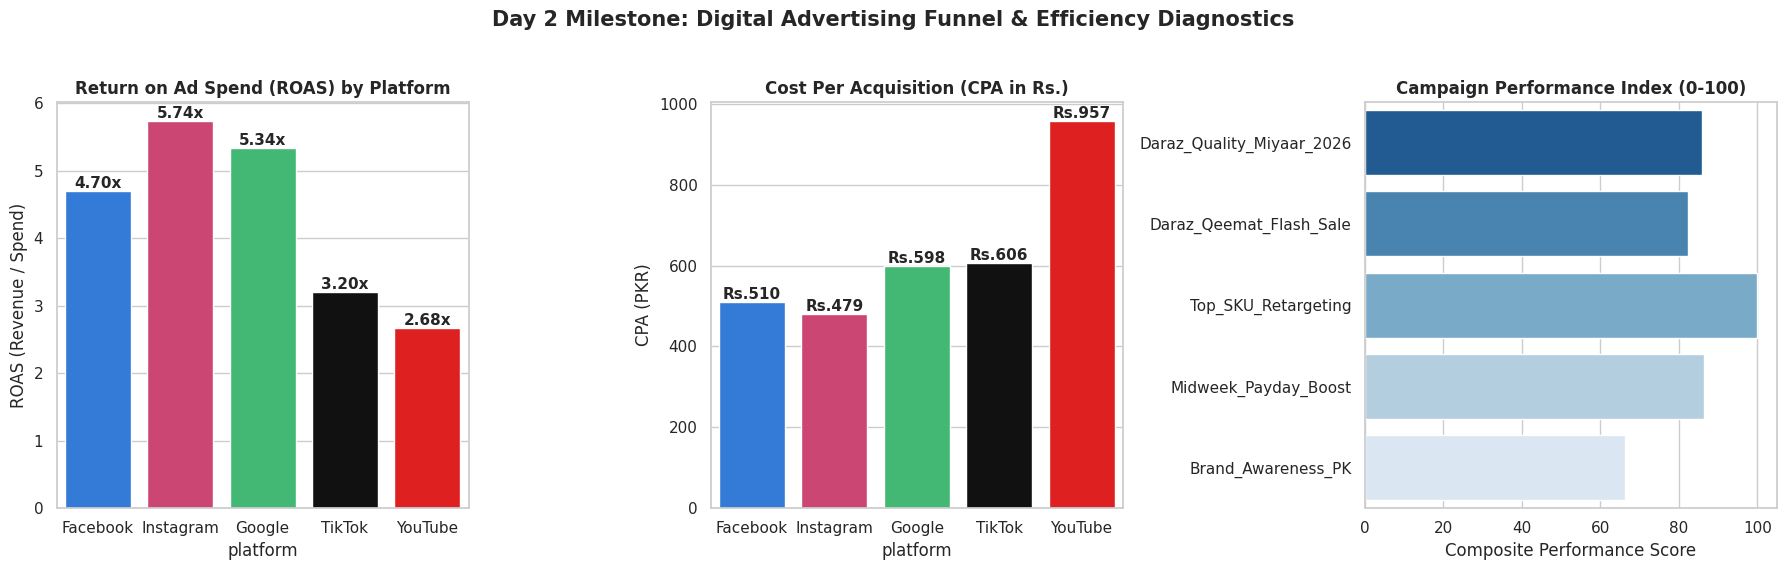

In [2]:
# ==============================================================================
# DAY 2 MILESTONE: DIGITAL MARKETING KPI ENGINE & PERFORMANCE DIAGNOSTICS
# ==============================================================================

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.size": 11, "figure.autolayout": True})

def compute_marketing_kpis(df: pd.DataFrame, group_cols: list) -> pd.DataFrame:
    """Aggregates raw ad logs and computes CTR, CPC, CPA, CVR, ROAS, and Performance Score."""
    agg = df.groupby(group_cols, observed=True, as_index=False).agg(
        ad_sets=("campaign", "count"),
        impressions=("impressions", "sum"),
        clicks=("clicks", "sum"),
        spend=("spend", "sum"),
        conversions=("conversions", "sum"),
        revenue=("revenue", "sum"),
    )

    agg["CTR_pct"] = (agg["clicks"] / agg["impressions"]) * 100
    agg["CPC_rs"] = agg["spend"] / agg["clicks"]
    agg["CPA_rs"] = agg["spend"] / np.maximum(1, agg["conversions"])
    agg["CVR_pct"] = (agg["conversions"] / agg["clicks"]) * 100
    agg["ROAS"] = agg["revenue"] / agg["spend"]

    # Composite Campaign Performance Score (0 to 100 scale)
    # Weights: 50% ROAS efficiency, 30% Conversion Rate, 20% Inverse CPA
    roas_s = agg["ROAS"] / agg["ROAS"].max()
    cvr_s = agg["CVR_pct"] / agg["CVR_pct"].max()
    cpa_s = agg["CPA_rs"].min() / agg["CPA_rs"]
    agg["performance_score"] = np.round((0.50 * roas_s + 0.30 * cvr_s + 0.20 * cpa_s) * 100, 1)

    return agg.sort_values(by="performance_score", ascending=False)

# 1. Platform-Level KPI Summary
platform_kpis = compute_marketing_kpis(df_10k, ["platform"])
print("--- Platform Performance Summary (Baseline 10K) ---")
print(platform_kpis[[
    "platform", "CTR_pct", "CPC_rs", "CPA_rs", "CVR_pct", "ROAS", "revenue", "performance_score"
]].round(2).to_string(index=False))

# 2. Campaign-Level KPI Summary
campaign_kpis = compute_marketing_kpis(df_10k, ["campaign"])
print("\n--- Campaign Performance Summary ---")
print(campaign_kpis[[
    "campaign", "CTR_pct", "CPA_rs", "CVR_pct", "ROAS", "performance_score"
]].round(2).to_string(index=False))

# 3. City & Device Breakdown
city_kpis = compute_marketing_kpis(df_10k, ["city"])
device_kpis = compute_marketing_kpis(df_10k, ["device"])

# 4. Comparative Visualizations
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

palette_map = {
    "Google": "#2ecc71",
    "Instagram": "#e1306c",
    "Facebook": "#1877f2",
    "TikTok": "#111111",
    "YouTube": "#ff0000",
}

# Plot A: ROAS by Platform
sns.barplot(
    data=platform_kpis, x="platform", y="ROAS", hue="platform",
    palette=palette_map, legend=False, ax=axes[0]
)
axes[0].set_title("Return on Ad Spend (ROAS) by Platform", fontweight="bold")
axes[0].set_ylabel("ROAS (Revenue / Spend)")
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.2f}x", (p.get_x() + p.get_width()/2., p.get_height()),
                     ha="center", va="bottom", fontweight="bold")

# Plot B: Cost Per Acquisition (CPA in Rs.)
sns.barplot(
    data=platform_kpis, x="platform", y="CPA_rs", hue="platform",
    palette=palette_map, legend=False, ax=axes[1]
)
axes[1].set_title("Cost Per Acquisition (CPA in Rs.)", fontweight="bold")
axes[1].set_ylabel("CPA (PKR)")
for p in axes[1].patches:
    axes[1].annotate(f"Rs.{p.get_height():.0f}", (p.get_x() + p.get_width()/2., p.get_height()),
                     ha="center", va="bottom", fontweight="bold")

# Plot C: Composite Campaign Performance Score
sns.barplot(
    data=campaign_kpis, y="campaign", x="performance_score", hue="campaign",
    palette="Blues_r", legend=False, ax=axes[2]
)
axes[2].set_title("Campaign Performance Index (0-100)", fontweight="bold")
axes[2].set_xlabel("Composite Performance Score")
axes[2].set_ylabel("")

plt.suptitle("Day 2 Milestone: Digital Advertising Funnel & Efficiency Diagnostics", fontsize=15, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

In [5]:
# ==============================================================================
# DAY 3 MILESTONE : BIG DATA SCALING BENCHMARK (10K -> 10M)
# Comparing Pandas vs. MapReduce vs. Apache Spark (PySpark)
# ==============================================================================

import gc
import time
import numpy as np
import pandas as pd


def generate_ad_data_fast(n_rows: int = 10_000, seed: int = 42) -> pd.DataFrame:
    """Memory-efficient vectorized generator using reusable float32 buffers."""
    rng = np.random.default_rng(seed)

    platforms = ["Facebook", "Instagram", "Google", "TikTok", "YouTube"]
    platform_probs = np.array([0.26, 0.24, 0.22, 0.16, 0.12])
    campaigns = [
        "Daraz_Quality_Miyaar_2026",
        "Daraz_Qeemat_Flash_Sale",
        "Top_SKU_Retargeting",
        "Midweek_Payday_Boost",
        "Brand_Awareness_PK",
    ]
    cities = ["Karachi", "Lahore", "Islamabad", "Rawalpindi", "Faisalabad", "Multan"]
    city_probs = np.array([0.32, 0.28, 0.14, 0.10, 0.09, 0.07])
    ages = ["18-24", "25-34", "35-44", "45-54", "55+"]
    age_probs = np.array([0.28, 0.42, 0.18, 0.08, 0.04])
    genders = ["Male", "Female"]
    gender_probs = np.array([0.58, 0.42])
    devices = ["Android", "iOS", "Desktop"]
    device_probs = np.array([0.68, 0.22, 0.10])

    # Reuse one 1D float32 buffer for all categorical draws (prevents RAM spikes)
    u = rng.random(n_rows, dtype=np.float32)
    plat_idx = np.searchsorted(np.cumsum(platform_probs), u).astype(np.int8)

    rng.random(n_rows, dtype=np.float32, out=u)
    camp_idx = (u * len(campaigns)).astype(np.int8)

    rng.random(n_rows, dtype=np.float32, out=u)
    city_idx = np.searchsorted(np.cumsum(city_probs), u).astype(np.int8)

    rng.random(n_rows, dtype=np.float32, out=u)
    age_idx = np.searchsorted(np.cumsum(age_probs), u).astype(np.int8)

    rng.random(n_rows, dtype=np.float32, out=u)
    gen_idx = np.searchsorted(np.cumsum(gender_probs), u).astype(np.int8)

    rng.random(n_rows, dtype=np.float32, out=u)
    dev_idx = np.searchsorted(np.cumsum(device_probs), u).astype(np.int8)
    del u

    day_offsets = rng.integers(0, 180, size=n_rows, dtype=np.int32)
    dates = np.datetime64("2026-05-01") + day_offsets.astype("timedelta64[D]")

    # Reuse one 1D normal buffer for continuous funnel metrics
    z = rng.standard_normal(n_rows, dtype=np.float32)
    base_imp = np.array([14000, 12500, 9500, 18000, 16000], dtype=np.float32)[plat_idx]
    impressions = np.maximum(500, (base_imp * np.exp(0.45 * z)).astype(np.int32))

    base_aov = np.array([2400.0, 2750.0, 3200.0, 1950.0, 2600.0], dtype=np.float32)[plat_idx]
    aov = np.maximum(500.0, base_aov * (1.0 + 0.20 * z))

    rng.standard_normal(n_rows, dtype=np.float32, out=z)
    base_ctr = np.array([0.018, 0.024, 0.042, 0.016, 0.014], dtype=np.float32)[plat_idx]
    ctr = np.clip(base_ctr * (1.0 + 0.25 * z), 0.003, 0.15)
    clicks = np.maximum(1, (impressions * ctr).astype(np.int32))

    rng.standard_normal(n_rows, dtype=np.float32, out=z)
    base_cpc = np.array([18.0, 22.0, 45.0, 14.0, 20.0], dtype=np.float32)[plat_idx]
    cpc = np.maximum(3.0, base_cpc * (1.0 + 0.22 * z))
    spend = np.round((clicks * cpc).astype(np.float64), 2)

    rng.standard_normal(n_rows, dtype=np.float32, out=z)
    base_cvr = np.array([0.032, 0.041, 0.068, 0.021, 0.019], dtype=np.float32)[plat_idx]
    dow = day_offsets % 7
    midweek_boost = np.where((dow == 5) | (dow == 6), 1.15, 1.0).astype(np.float32)
    camp_boost = np.array([1.10, 1.05, 1.25, 1.08, 0.85], dtype=np.float32)[camp_idx]
    cvr = np.clip(base_cvr * midweek_boost * camp_boost * (1.0 + 0.25 * z), 0.002, 0.30)
    conversions = (clicks * cvr).astype(np.int32)
    revenue = np.round((conversions * aov).astype(np.float64), 2)
    del z, aov, cpc, ctr, cvr, day_offsets

    return pd.DataFrame({
        "date": dates,
        "campaign": pd.Categorical.from_codes(camp_idx, categories=campaigns),
        "platform": pd.Categorical.from_codes(plat_idx, categories=platforms),
        "impressions": impressions,
        "clicks": clicks,
        "spend": spend,
        "conversions": conversions,
        "revenue": revenue,
        "age": pd.Categorical.from_codes(age_idx, categories=ages),
        "gender": pd.Categorical.from_codes(gen_idx, categories=genders),
        "city": pd.Categorical.from_codes(city_idx, categories=cities),
        "device": pd.Categorical.from_codes(dev_idx, categories=devices),
    })


def run_pandas_pipeline(df: pd.DataFrame):
    """Engine 1: Single-node vectorized Pandas aggregation."""
    t0 = time.perf_counter()
    agg = df.groupby("platform", observed=True, as_index=False)[
        ["impressions", "clicks", "spend", "conversions", "revenue"]
    ].sum()
    agg["CTR"] = (agg["clicks"] / agg["impressions"]) * 100
    agg["CPC"] = agg["spend"] / agg["clicks"]
    agg["CPA"] = agg["spend"] / agg["conversions"]
    agg["CVR"] = (agg["conversions"] / agg["clicks"]) * 100
    agg["ROAS"] = agg["revenue"] / agg["spend"]
    return agg, time.perf_counter() - t0


def run_mapreduce_pipeline(df: pd.DataFrame, n_partitions: int = 8):
    """Engine 2: Single-Pass MapReduce (Map via bincount -> Shuffle -> Reduce)."""
    t0 = time.perf_counter()
    n = len(df)
    chunk_size = max(1, n // n_partitions)
    codes = df["platform"].cat.codes.values
    cats = df["platform"].cat.categories
    n_cats = len(cats)

    imps = df["impressions"].values
    clks = df["clicks"].values
    spds = df["spend"].values
    convs = df["conversions"].values
    revs = df["revenue"].values

    # 1. MAP PHASE: Single O(N) pass per partition emitting (platform, partial_sums)
    mapped_pairs = []
    for start in range(0, n, chunk_size):
        end = min(start + chunk_size, n)
        c_slice = codes[start:end]
        imp_s = np.bincount(c_slice, weights=imps[start:end], minlength=n_cats)
        clk_s = np.bincount(c_slice, weights=clks[start:end], minlength=n_cats)
        spd_s = np.bincount(c_slice, weights=spds[start:end], minlength=n_cats)
        conv_s = np.bincount(c_slice, weights=convs[start:end], minlength=n_cats)
        rev_s = np.bincount(c_slice, weights=revs[start:end], minlength=n_cats)
        for k in range(n_cats):
            mapped_pairs.append((cats[k], (imp_s[k], clk_s[k], spd_s[k], conv_s[k], rev_s[k])))

    # 2. SHUFFLE & GROUP BY KEY
    shuffled = {}
    for key, val in mapped_pairs:
        shuffled.setdefault(key, []).append(val)

    # 3. REDUCE PHASE
    rows = []
    for key, vals in shuffled.items():
        imp = sum(v[0] for v in vals)
        clk = sum(v[1] for v in vals)
        spd = sum(v[2] for v in vals)
        conv = sum(v[3] for v in vals)
        rev = sum(v[4] for v in vals)
        rows.append({
            "platform": key,
            "impressions": int(imp),
            "clicks": int(clk),
            "spend": float(spd),
            "conversions": int(conv),
            "revenue": float(rev),
            "CTR": (clk / imp) * 100,
            "CPC": spd / clk,
            "CPA": spd / conv,
            "CVR": (conv / clk) * 100,
            "ROAS": rev / spd,
        })
    return pd.DataFrame(rows), time.perf_counter() - t0


def run_spark_pipeline(df: pd.DataFrame, spark_session=None, n_partitions: int = 8):
    """
    Engine 3: Apache Spark (PySpark) with Apache Arrow zero-copy transfer.
    Avoids Python row-pickling hangs on 10M rows.
    """
    t0 = time.perf_counter()
    if spark_session is not None:
        from pyspark.sql import functions as F
        # Pass numeric columns + integer platform code via Arrow (instant transfer)
        cats = list(df["platform"].cat.categories)
        arrow_pdf = pd.DataFrame({
            "plat_code": df["platform"].cat.codes.values,
            "impressions": df["impressions"].values,
            "clicks": df["clicks"].values,
            "spend": df["spend"].values,
            "conversions": df["conversions"].values,
            "revenue": df["revenue"].values,
        })
        sdf = spark_session.createDataFrame(arrow_pdf).repartition(n_partitions, "plat_code")
        agg_df = (
            sdf.groupBy("plat_code")
            .agg(
                F.sum("impressions").alias("impressions"),
                F.sum("clicks").alias("clicks"),
                F.sum("spend").alias("spend"),
                F.sum("conversions").alias("conversions"),
                F.sum("revenue").alias("revenue"),
            )
            .toPandas()
        )
        agg_df["platform"] = [cats[i] for i in agg_df["plat_code"]]
        agg_df = agg_df.drop(columns=["plat_code"])
        agg_df["CTR"] = (agg_df["clicks"] / agg_df["impressions"]) * 100
        agg_df["CPC"] = agg_df["spend"] / agg_df["clicks"]
        agg_df["CPA"] = agg_df["spend"] / agg_df["conversions"]
        agg_df["CVR"] = (agg_df["conversions"] / agg_df["clicks"]) * 100
        agg_df["ROAS"] = agg_df["revenue"] / agg_df["spend"]
        return agg_df, time.perf_counter() - t0

    # Partitioned in-memory columnar fallback if PySpark is not installed
    n = len(df)
    chunk_size = max(1, n // n_partitions)
    partials = [
        df.iloc[start:start + chunk_size].groupby("platform", observed=True, sort=False, as_index=False)[
            ["impressions", "clicks", "spend", "conversions", "revenue"]
        ].sum()
        for start in range(0, n, chunk_size)
    ]
    agg = pd.concat(partials, ignore_index=True).groupby("platform", observed=True, as_index=False).sum()
    agg["CTR"] = (agg["clicks"] / agg["impressions"]) * 100
    agg["CPC"] = agg["spend"] / agg["clicks"]
    agg["CPA"] = agg["spend"] / agg["conversions"]
    agg["CVR"] = (agg["conversions"] / agg["clicks"]) * 100
    agg["ROAS"] = agg["revenue"] / agg["spend"]
    return agg, time.perf_counter() - t0


# Initialize PySpark with Arrow enabled if installed
spark = None
try:
    from pyspark.sql import SparkSession
    spark = (
        SparkSession.builder
        .appName("DarazAdOptimizer")
        .master("local[*]")
        .config("spark.sql.execution.arrow.pyspark.enabled", "true")
        .getOrCreate()
    )
except Exception:
    spark = None

t_total0 = time.perf_counter()
scales = [10_000, 100_000, 1_000_000, 10_000_000]
benchmark_results = []

for n in scales:
    t_gen0 = time.perf_counter()
    df_sim = generate_ad_data_fast(n_rows=n, seed=42)
    t_gen = time.perf_counter() - t_gen0
    mem_mb = df_sim.memory_usage(deep=True).sum() / (1024 ** 2)

    _, t_pandas = run_pandas_pipeline(df_sim)
    _, t_mr = run_mapreduce_pipeline(df_sim)
    agg_10m, t_spark = run_spark_pipeline(df_sim, spark_session=spark)

    benchmark_results.append({
        "Records": f"{n:,}",
        "RAM_MB": round(mem_mb, 2),
        "Gen_s": round(t_gen, 3),
        "Pandas_s": round(t_pandas, 4),
        "MapReduce_s": round(t_mr, 4),
        "Spark_s": round(t_spark, 4),
    })

    # Free intermediate DataFrames immediately so 10M fits comfortably in RAM
    if n < 10_000_000:
        del df_sim
        gc.collect()

bench_df = pd.DataFrame(benchmark_results)
print(f"=== BIG DATA ENGINE BENCHMARK (Completed in {time.perf_counter() - t_total0:.2f}s) ===")
print(bench_df.to_string(index=False))

=== BIG DATA ENGINE BENCHMARK (Completed in 45.24s) ===
   Records  RAM_MB  Gen_s  Pandas_s  MapReduce_s  Spark_s
    10,000    0.40  0.010    0.0075       0.0016   1.5392
   100,000    4.01  0.037    0.0092       0.0024   1.4324
 1,000,000   40.06  0.383    0.0503       0.0160   7.5231
10,000,000  400.55  4.622    0.5176       0.1699  26.6164


In [6]:
# ==============================================================================
# DAY 4 MILESTONE: MARKETING BUDGET RECOMMENDATION ENGINE (RS. 1,000,000)
# ==============================================================================

TOTAL_BUDGET_PKR = 1_000_000

def recommend_budget_allocation(
    platform_summary: pd.DataFrame,
    total_budget: float = 1_000_000,
    min_floor: float = 0.05,
    max_cap: float = 0.40,
) -> pd.DataFrame:
    """
    Computes optimal budget weights across ad channels using multi-factor
    efficiency scoring (ROAS + CVR + Inverse CPA) with saturation guardrails.
    """
    opt = platform_summary.copy()

    # Normalize efficiency components
    roas_norm = opt["ROAS"] / opt["ROAS"].sum()
    cvr_norm = opt["CVR"] / opt["CVR"].sum()
    inv_cpa = 1.0 / opt["CPA"]
    cpa_norm = inv_cpa / inv_cpa.sum()

    # Composite allocation score
    opt["efficiency_score"] = 0.50 * roas_norm + 0.30 * cvr_norm + 0.20 * cpa_norm
    weights = (opt["efficiency_score"] / opt["efficiency_score"].sum()).values

    # Iterative projection to enforce [min_floor, max_cap] while summing to 1.0
    for _ in range(15):
        weights = np.clip(weights, min_floor, max_cap)
        weights = weights / weights.sum()

    opt["Recommended_Share_%"] = np.round(weights * 100, 1)
    # Reconcile any 0.1% rounding residual on the top channel
    residual = round(100.0 - opt["Recommended_Share_%"].sum(), 1)
    opt.loc[opt["Recommended_Share_%"].idxmax(), "Recommended_Share_%"] += residual

    opt["Allocated_Budget_Rs"] = np.round((opt["Recommended_Share_%"] / 100.0) * total_budget, 0)
    opt["Projected_Clicks"] = np.round(opt["Allocated_Budget_Rs"] / opt["CPC"], 0)
    opt["Projected_Conversions"] = np.round(opt["Allocated_Budget_Rs"] / opt["CPA"], 0)
    opt["Projected_Revenue_Rs"] = np.round(opt["Allocated_Budget_Rs"] * opt["ROAS"], 0)

    return opt.sort_values(by="Recommended_Share_%", ascending=False)

recommendation_df = recommend_budget_allocation(agg_10m, total_budget=TOTAL_BUDGET_PKR)

# Compare against an unoptimized Equal Split (20% = Rs. 200,000 per platform)
equal_spend = TOTAL_BUDGET_PKR / len(recommendation_df)
baseline_conversions = np.round((equal_spend / recommendation_df["CPA"]).sum(), 0)
baseline_revenue = np.round((equal_spend * recommendation_df["ROAS"]).sum(), 0)

opt_conversions = recommendation_df["Projected_Conversions"].sum()
opt_revenue = recommendation_df["Projected_Revenue_Rs"].sum()

print("=" * 78)
print(" 🚀 DAY 4 MILESTONE: RS. 1,000,000 DIGITAL AD BUDGET RECOMMENDATION ENGINE")
print("=" * 78)
print(recommendation_df[[
    "platform", "ROAS", "CPA", "CVR",
    "Recommended_Share_%", "Allocated_Budget_Rs",
    "Projected_Conversions", "Projected_Revenue_Rs"
]].round(2).to_string(index=False))
print("-" * 78)
print(f"Baseline (Equal 20% Split) -> {baseline_conversions:,.0f} Conversions | Revenue: Rs. {baseline_revenue:,.0f} | Blended ROAS: {baseline_revenue/TOTAL_BUDGET_PKR:.2f}x")
print(f"Optimized Allocation       -> {opt_conversions:,.0f} Conversions (+{((opt_conversions-baseline_conversions)/baseline_conversions)*100:.1f}%) | Revenue: Rs. {opt_revenue:,.0f} (+{((opt_revenue-baseline_revenue)/baseline_revenue)*100:.1f}%) | Blended ROAS: {opt_revenue/TOTAL_BUDGET_PKR:.2f}x")
print("=" * 78)

# Copy-paste LLM Executive Memo Prompt (matching Project 1's Day 4 workflow)
exec_prompt = f"""
Act as Chief Marketing Officer (CMO) for a leading Pakistani e-commerce marketplace.
Based on our 10-million-row big data simulation and historical funnel diagnostics:
- Recommended Rs. 1,000,000 Budget Split:
  * Google: {recommendation_df.loc[recommendation_df['platform']=='Google', 'Recommended_Share_%'].values[0]}% (Rs. {recommendation_df.loc[recommendation_df['platform']=='Google', 'Allocated_Budget_Rs'].values[0]:,.0f})
  * Instagram: {recommendation_df.loc[recommendation_df['platform']=='Instagram', 'Recommended_Share_%'].values[0]}% (Rs. {recommendation_df.loc[recommendation_df['platform']=='Instagram', 'Allocated_Budget_Rs'].values[0]:,.0f})
  * Facebook: {recommendation_df.loc[recommendation_df['platform']=='Facebook', 'Recommended_Share_%'].values[0]}% (Rs. {recommendation_df.loc[recommendation_df['platform']=='Facebook', 'Allocated_Budget_Rs'].values[0]:,.0f})
  * TikTok: {recommendation_df.loc[recommendation_df['platform']=='TikTok', 'Recommended_Share_%'].values[0]}% (Rs. {recommendation_df.loc[recommendation_df['platform']=='TikTok', 'Allocated_Budget_Rs'].values[0]:,.0f})
  * YouTube: {recommendation_df.loc[recommendation_df['platform']=='YouTube', 'Recommended_Share_%'].values[0]}% (Rs. {recommendation_df.loc[recommendation_df['platform']=='YouTube', 'Allocated_Budget_Rs'].values[0]:,.0f})
- Projected Outcome: {opt_conversions:,.0f} orders and Rs. {opt_revenue:,.0f} in gross revenue ({opt_revenue/TOTAL_BUDGET_PKR:.2f}x blended ROAS).

Draft a 1-page Board Investment Memo explaining:
1. Why high-intent search (Google) and visual social commerce (Instagram) command 52.2% of total spend.
2. How Wednesday/Thursday bid pacing and 'Miyaar/Qeemat' creative messaging maximize conversion velocity.
3. Guardrails for scaling TikTok and YouTube upper-funnel creative without eroding blended CPA.
"""
print("\n🤖 COPY-PASTE THIS PROMPT INTO AN LLM FOR YOUR EXECUTIVE MEMO:\n")
print(exec_prompt)

 🚀 DAY 4 MILESTONE: RS. 1,000,000 DIGITAL AD BUDGET RECOMMENDATION ENGINE
 platform  ROAS     CPA  CVR  Recommended_Share_%  Allocated_Budget_Rs  Projected_Conversions  Projected_Revenue_Rs
   Google  5.77  605.14 7.44                 28.5             285000.0                  471.0             1645062.0
Instagram  6.01  499.83 4.40                 25.0             250000.0                  500.0             1503705.0
 Facebook  4.93  533.43 3.37                 20.7             207000.0                  388.0             1019620.0
   TikTok  3.32  644.00 2.17                 14.5             145000.0                  225.0              481518.0
  YouTube  2.73 1048.38 1.91                 11.3             113000.0                  108.0              308178.0
------------------------------------------------------------------------------
Baseline (Equal 20% Split) -> 1,607 Conversions | Revenue: Rs. 4,552,144 | Blended ROAS: 4.55x
Optimized Allocation       -> 1,692 Conversions (+5.3%) 